# **Module 01: Types of Variables, Measurement Scales, and Precision**

---

## 📌 Overview

Before applying any statistical technique, building a chart, or training a Machine Learning model, it is essential to understand the nature of the data collected. Most analytical mistakes start at the very beginning: treating a variable as if it possessed mathematical properties that it does not actually have.

In this notebook, we will establish the conceptual foundation for classifying variables, identifying their measurement scales, and evaluating the quality and reliability of measurements.

---

## 🎯 Learning Objectives

By the end of this module, you will be able to:

* **Classify variables accurately** into qualitative (nominal and ordinal) and quantitative (discrete and continuous) types.
* **Identify the four measurement scales** (nominal, ordinal, interval, and ratio) and determine which mathematical and statistical operations are valid for each.
* **Distinguish between precision and accuracy**, recognizing the impact of systematic errors (bias) and random errors (noise) on data quality.
* **Evaluate measurement quality** using the concepts of validity and reliability.
* **Avoid common practical pitfalls**, such as performing arithmetic on numeric codes, misinterpreting ordinal scales, or reporting false precision.

---

## 🧭 Module Structure

1. **Types of Variables** — Qualitative (nominal, ordinal) and quantitative (discrete, continuous) classifications.
2. **Measurement Scales** — Nominal, ordinal, interval, and ratio levels, and their permitted operations.
3. **Precision, Accuracy, and Measurement Errors** — Bias vs. noise, validity, and reliability.
4. **Common Practical Pitfalls** — Numeric identifiers, ordinal arithmetic, and false precision.
5. **Hands-on Python** — Inspecting, converting, and validating variable data types using `pandas` and `numpy`.

---

## 🛠️ Technical Requirements

* Basic familiarity with Python syntax.
* Python environment configured with: `numpy` and `pandas`.

## Python Virtual Environment Setup

### 1. Create the virtual environment

```bash
python3 -m venv .venv
```

### 2. Activate the virtual environment
Linux / macOS:

```bash
source .venv/bin/activate
```

Windows (PowerShell):

```PowerShell
.\.venv\Scripts\Activate.ps1
```
Windows (Command Prompt):

```DOS
.venv\Scripts\activate.bat
```

###  3. Upgrade pip and install dependencies (optional)
```bash
pip install --upgrade pip
pip install -r requirements.txt
```

### 4. Deactivate the virtual environment
```bash
deactivate
```

In [12]:
#Devemos instalar as mesmas primeiramento
%pip install  pandas numpy matplotlib 

  Using cached matplotlib-3.11.2-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.68.0-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (139 kB)
  Using cached kiwisolver-1.5.1-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.1 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl (9.9 MB)
Using cached contourpy-1.4.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (383 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.68.0-cp312-cp312-manylinux2014_x86_64.manylinux_2_17

In [13]:
#importar bibliotecas
import pandas as pd
import numpy as np
import matplotlib as plt
import math

## 1. Tipos de Variáveis

Uma **variável** é qualquer característica, atributo ou quantidade observada em um conjunto de elementos (pessoas, sensores, transações, municípios) que pode assumir diferentes valores entre uma observação e outra.

De modo geral, as variáveis dividem-se em dois grandes grupos: **qualitativas** (categóricas) e **quantitativas** (numéricas).

### 1.1 Variáveis Qualitativas (Categóricas)

Expressam atributos, rótulos ou qualidades que não representam uma quantidade física mensurável.

* **Qualitativa Nominal:** os valores servem apenas para nomear ou categorizar grupos, sem qualquer relação de ordem ou hierarquia entre eles.
  * *Exemplos:* sistema operacional (`Linux`, `Windows`, `macOS`), forma de pagamento (`Pix`, `Cartão`, `Boleto`), estado civil.
* **Qualitativa Ordinal:** além de categorizar, existe uma ordenação natural entre as classes, embora a distância exata entre um nível e outro não seja mensurável.
  * *Exemplos:* nível de escolaridade (`Fundamental`, `Médio`, `Superior`), prioridade de chamado (`Baixa`, `Média`, `Alta`, `Crítica`), faixa de avaliação de satisfação.

### 1.2 Variáveis Quantitativas (Numéricas)

Representam contagens ou medições expressas em números reais, permitindo operações aritméticas com significado prático.

* **Quantitativa Discreta:** resulta geralmente de um processo de contagem e assume valores isolados (finitos ou enumeráveis), sem valores intermediários válidos entre dois números consecutivos.
  * *Exemplos:* número de requisições por minuto, quantidade de filhos, total de erros registrados em um *log*.
* **Quantitativa Contínua:** resulta de um processo de medição e pode assumir qualquer valor dentro de um intervalo real, limitado apenas pela capacidade do instrumento de medida.
  * *Exemplos:* tempo de latência de um servidor (em milissegundos), temperatura ambiente, peso de uma carga, distância percorrida.

### Quadro-Resumo e Mapeamento para Ciência de Dados

| Classificação | Subtipo | Exemplo Prático | Representação Típica (Python/Pandas) |
| :--- | :--- | :--- | :--- |
| **Qualitativa** | Nominal | Categoria de produto | `object` / `category` (não ordenado) |
| **Qualitativa** | Ordinal | Grau de risco (Baixo, Médio, Alto) | `category` (`ordered=True`) |
| **Quantitativa** | Discreta | Quantidade de itens no carrinho | `int64` |
| **Quantitativa** | Contínua | Tempo de resposta em segundos | `float64` |

-?

*   `Variáveis não métricas:` também chamadas de categóricas ou qualitativas, representam características dos indivíduos que não podem ser medidas, apenas classificadas.
*   `Variáveis métricas:` também chamadas de quantitativas, representam características dos indivíduos que resultam de contagens ou mensurações.

## **Variáveis não métricas**

In [3]:
#Criando dados
clas_salarios = [
                  ['A', 'Acima de 20 SM', 'Acima de R$ 15760.00'],
                  ['B', '10 a 20 SM', 'De R$ 7880.00 a R$ 15760.00'],
                  ['C', '4 a 10 SM', 'De R$ 3152.00 a R$ 7880.00'],
                  ['D', '2 a 4 SM', 'De R$ 1576.00 a R$ 3152.00'],
                  ['E', 'Até 2 SM', 'Até R$ 1576.00']
                ]

colunas = ['Classe', 'Salário Mínimo (SM)', 'Renda Familiar (RF)']

In [4]:
#Mostrando DataFrame
clas_salrios = pd.DataFrame(clas_salarios)
clas_salrios.columns = colunas
clas_salrios

,Classe,Salário Mínimo (SM),Renda Familiar (RF)
0,A,Acima de 20 SM,Acima de R$ 15760.00
1,B,10 a 20 SM,De R$ 7880.00 a R$ 15760.00
2,C,4 a 10 SM,De R$ 3152.00 a R$ 7880.00
3,D,2 a 4 SM,De R$ 1576.00 a R$ 3152.00
4,E,Até 2 SM,Até R$ 1576.00


Note que os dados estão divididos em faixas, sendo então qualitativos. Nesse caso podemos calcular frequências, mas não medidas de resumo como média e desvio-padrão.

`OBS:` *Cuidado ao usar as informações numéricas dessas faixas, não as trate como se fossem um dado quantitativo.*

Podemos, por exemplo, ver quanto cada uma das classes se repete, ou seja, a frequência de cada classe.

In [5]:
clas_salrios["Frequência"] = ["10%", "18%", "24%", "36%", "12%"]
clas_salrios

,Classe,Salário Mínimo (SM),Renda Familiar (RF),Frequência
0,A,Acima de 20 SM,Acima de R$ 15760.00,10%
1,B,10 a 20 SM,De R$ 7880.00 a R$ 15760.00,18%
2,C,4 a 10 SM,De R$ 3152.00 a R$ 7880.00,24%
3,D,2 a 4 SM,De R$ 1576.00 a R$ 3152.00,36%
4,E,Até 2 SM,Até R$ 1576.00,12%


## **Variáveis métricas**

Variáveis quantitativas podem ser representadas por gráficos de linha, de dispersão, histogramas ... e resumidas por medidas de posição (média, mediana, moda, quartis ...) e de dispersão (amplitude, desvios, variância ...).

In [6]:
#Criando dados
dados = [['João', 48, 5000, 4, 2000, 'Brasil', 'D'],
         ['Maria', 23, 1500, 1, 5000, 'Argentina', 'C'],
         ['José', 47, 9000, 10, 9000, 'Brasil', 'C'],
         ['Frank', 19, 400, 0, 3000, 'Marrocos', 'D'],
         ['Mario', 33, 3400, 3, 3400, 'Alemanha', 'D']]


colunas = ['Nome', 'Idade', 'Salário', 'Tempo Experiência', 'Renda Familiar', 'Pais de Origem', 'Classe']

In [7]:
df = pd.DataFrame(dados)
df.columns = colunas
df

,Nome,Idade,Salário,Tempo Experiência,Renda Familiar,Pais de Origem,Classe
0,João,48,5000,4,2000,Brasil,D
1,Maria,23,1500,1,5000,Argentina,C
2,José,47,9000,10,9000,Brasil,C
3,Frank,19,400,0,3000,Marrocos,D
4,Mario,33,3400,3,3400,Alemanha,D


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   Nome               5 non-null      str  
 1   Idade              5 non-null      int64
 2   Salário            5 non-null      int64
 3   Tempo Experiência  5 non-null      int64
 4   Renda Familiar     5 non-null      int64
 5   Pais de Origem     5 non-null      str  
 6   Classe             5 non-null      str  
dtypes: int64(4), str(3)
memory usage: 412.0 bytes


Note que as únicas variáveis textuais são o nome da pessoa, o país de origem e a classe, que são qualitativas: `Nome` e `Pais de Origem` estão em escala nominal e `Classe` em escala ordinal. As demais são quantitativas, resultado de contagens ou mensurações.

## **Tipos de Variáveis vs. Escalas de Mensuração**

`Mensuração:` processo de atribuir números ou rótulos aos objetos de estudo, com base em regras específicas, para representar as quantidades ou qualidades dos seus atributos.

`Regra:` guia, método ou comando que indica como medir o atributo.

`Escala:` conjunto de símbolos ou números construídos com base na regra e aplicados a cada objeto.

* `Variáveis qualitativas` $\rightarrow$ escala nominal ou ordinal
* `Variáveis quantitativas` $\rightarrow$ escala intervalar ou de razão

### **Escala Nominal**
Variáveis não métricas

Nessa escala as categorias não estabelecem qualquer grandeza ou ordem, sendo diferenciadas apenas pelos nomes.

Podemos atribuir rótulos numéricos às categorias, mas operações aritméticas com eles não fazem sentido. É possível contar o número de elementos de cada classe, calcular a moda e aplicar testes de hipóteses próprios para dados categóricos.

*Ex: profissão, religião, cor, estado civil, localização geográfica.*

`OBS:` *A maioria das estatísticas, como média e desvio-padrão, não tem sentido para dados nominais.*

Podemos, por exemplo, usar rótulos numéricos para representar cada categoria e facilitar a sua identificação.

In [9]:
#Representação por rótulos numéricos
rep_nominal = {"Brasil": 12, "Argentina": 25, "Marrocos": 32, "Alemanha": 45}
df["Rótulo"] = df["Pais de Origem"].map(rep_nominal)
df

,Nome,Idade,Salário,Tempo Experiência,Renda Familiar,Pais de Origem,Classe,Rótulo
0,João,48,5000,4,2000,Brasil,D,12
1,Maria,23,1500,1,5000,Argentina,C,25
2,José,47,9000,10,9000,Brasil,C,12
3,Frank,19,400,0,3000,Marrocos,D,32
4,Mario,33,3400,3,3400,Alemanha,D,45


Os rótulos da escala nominal são atribuídos de forma arbitrária às categorias. A partir deles podemos descrever os dados por meio de tabelas de distribuição de frequências, gráficos de barras ou de setores e pelo cálculo da moda.

In [10]:
cont_pais = pd.DataFrame(df.iloc[:, [5, 7]].value_counts())
cont_pais

,,count
Pais de Origem,Rótulo,
Brasil,12,2
Argentina,25,1
Marrocos,32,1
Alemanha,45,1


A partir dessa contagem podemos identificar qual país de origem mais se repete entre as pessoas listadas.

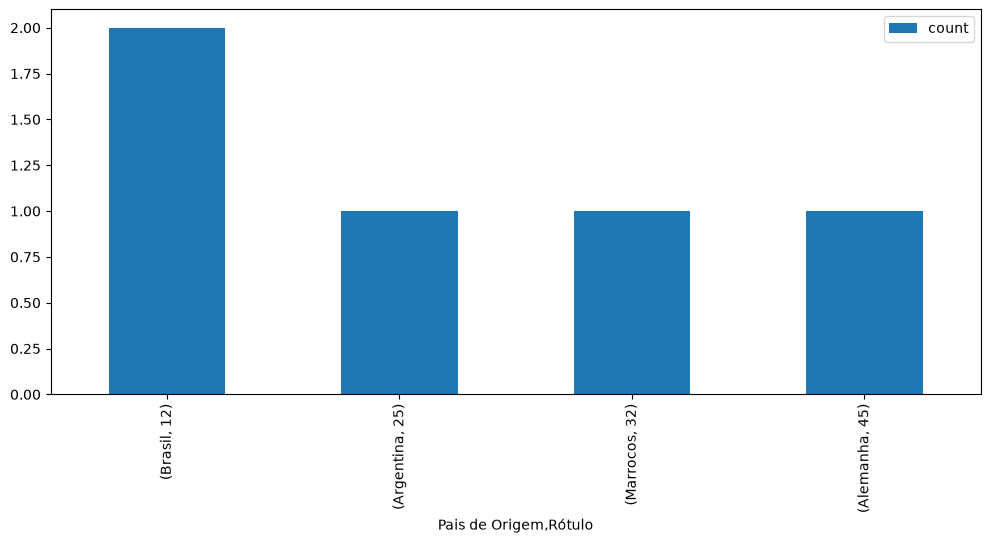

In [14]:
cont_pais.plot(kind = "bar", figsize = (12, 5));

### **Escala Ordinal**
Variáveis não métricas

Basicamente é uma variável categórica cujas classes têm uma posição relativa, seguindo uma ordem. Assim como na escala nominal, operações aritméticas não fazem sentido, e as estatísticas descritivas ficam limitadas a tabelas de distribuição de frequências, gráficos, moda e medidas separatrizes como a mediana.

*Ex: escala de opinião, escala de preferência, grau de escolaridade, classe social, faixa etária ...*

In [15]:
escala_valores = pd.DataFrame([[1, "Péssimo"],
                               [2, "Ruim"],
                               [3, "Regular"],
                               [4, "Bom"],
                               [5, "Muito Bom"]])

escala_valores.columns = ["Valor", "Rótulo"]
escala_valores

,Valor,Rótulo
0,1,Péssimo
1,2,Ruim
2,3,Regular
3,4,Bom
4,5,Muito Bom


Em vez da escala de 1 a 5 poderia ser usada qualquer outra escala numérica, desde que a ordem da classificação fosse respeitada.

In [16]:
clas_salrios

,Classe,Salário Mínimo (SM),Renda Familiar (RF),Frequência
0,A,Acima de 20 SM,Acima de R$ 15760.00,10%
1,B,10 a 20 SM,De R$ 7880.00 a R$ 15760.00,18%
2,C,4 a 10 SM,De R$ 3152.00 a R$ 7880.00,24%
3,D,2 a 4 SM,De R$ 1576.00 a R$ 3152.00,36%
4,E,Até 2 SM,Até R$ 1576.00,12%


In [17]:
cont_classe = df["Classe"].value_counts().reset_index()
cont_classe.columns = ["Classe", "Pessoas"]
cont_classe = pd.merge(clas_salrios, cont_classe, how = "left", on = ["Classe"])
cont_classe = cont_classe[cont_classe["Pessoas"] > 0]
cont_classe

,Classe,Salário Mínimo (SM),Renda Familiar (RF),Frequência,Pessoas
2,C,4 a 10 SM,De R$ 3152.00 a R$ 7880.00,24%,2.0
3,D,2 a 4 SM,De R$ 1576.00 a R$ 3152.00,36%,3.0


### **Escala Intervalar**
Variáveis quantitativas

Basicamente são variáveis métricas que, além de ordenar as unidades quanto à característica medida, possuem uma unidade de medida constante. Porém a origem (o zero) é arbitrária e não significa ausência da quantidade, como na temperatura em °C e °F.

A escala intervalar é invariante sob transformações lineares positivas, de modo que uma escala pode ser convertida em outra por uma transformação linear, como de °F para °C.

`OBS:` *Comprimentos (cm, m, km) também são convertidos por transformações lineares, mas, como têm um zero absoluto, pertencem à escala de razão.*

In [18]:
#Converter de centímetro para metro
def converter_cm_m(medicao):
    return print(f"{medicao * 0.01} m")

In [19]:
converter_cm_m(100)

1.0 m


In [20]:
#Converter Fahrenheit para Celsius
def converter_f_c(medicao):
    return print(f"{np.round((medicao - 32) * 5/9, 2)} °C")

In [17]:
converter_f_c(10)

-12.22 °C


### **Escala de Razão**
Variáveis quantitativas

Essa escala é análoga à intervalar: ordena as unidades em relação à característica medida e possui uma unidade de medida constante. A diferença é que a origem é única e o valor zero significa ausência da quantidade.

Por isso razões entre valores fazem sentido: se um objeto mede 1 metro e outro 3 metros, o segundo tem 3 vezes o comprimento do primeiro.

*Ex: renda, idade, quantidade produzida de determinado produto, distância percorrida.*

In [18]:
joao = df[df["Nome"] == 'João']
jose = df[df["Nome"] == "José"]

In [19]:
#Índice salarial
salario_joao = joao["Salário"].iloc[0]
salario_jose = jose["Salário"].iloc[0]

print(f"Salário João é de R$ {salario_joao}")
print(f"Salário José é de R$ {salario_jose}")

print(f"Diferença de salário entre João e José é de: R$ {salario_joao - salario_jose}")
print(f"O salário de João equivale a {np.round(salario_joao / salario_jose * 100, 2)}% do salário de José")
print(f"João ganha {np.round((1 - salario_joao / salario_jose) * 100, 2)}% menos que José")

Salário João é de R$ 5000
Salário José é de R$ 9000
Diferença de salário entre João e José é de: R$ -4000
O salário de João equivale a 55.56% do salário de José
João ganha 44.44% menos que José


## **Tipos de Variáveis vs. Número de Categorias e Escala de Precisão**

*   `Categórica` $\rightarrow$ dicotômica/binária ou policotômica
*   `Métrica` $\rightarrow$ discreta ou contínua

### **Variável dicotômica ou binária (dummy)**
Variáveis não métricas

Esse tipo de variável assume apenas duas categorias, sendo `0` a ausência e `1` a presença da característica.

*Ex: fumante (1) e não fumante (0)*

In [20]:
df_dummy = pd.get_dummies(df, columns=["Classe"], dtype=int)
df_dummy["Classe_A"] = 0
df_dummy["Classe_B"] = 0
df_dummy["Classe_E"] = 0
df_dummy[["Nome", "Classe_C", "Classe_D",  "Classe_A",  "Classe_B", "Classe_E"]]

,Nome,Classe_C,Classe_D,Classe_A,Classe_B,Classe_E
0,João,0,1,0,0,0
1,Maria,1,0,0,0,0
2,José,1,0,0,0,0
3,Frank,0,1,0,0,0
4,Mario,0,1,0,0,0


### **Variável policotômica**
Variáveis não métricas

Neste caso a variável pode assumir mais de duas categorias.

*Ex: baixa renda (1), média renda (2), alta renda (3)*

In [21]:
novo_dado = {"Nome":"Manoel", "Idade":33, "Salário":1200, "Tempo Experiência":1,
             "Renda Familiar":1200, "Pais de Origem":"Brasil", "Classe":"E"}

#Adicionando novo dado no DataFrame
df = pd.concat([df, pd.DataFrame([novo_dado])], ignore_index=True)
df

,Nome,Idade,Salário,Tempo Experiência,Renda Familiar,Pais de Origem,Classe,Rótulo
0,João,48,5000,4,2000,Brasil,D,12.0
1,Maria,23,1500,1,5000,Argentina,C,25.0
2,José,47,9000,10,9000,Brasil,C,12.0
3,Frank,19,400,0,3000,Marrocos,D,32.0
4,Mario,33,3400,3,3400,Alemanha,D,45.0
5,Manoel,33,1200,1,1200,Brasil,E,NaN


In [22]:
#Criando rotulos de várias classes
df["Rótulo"] = df.Classe.astype("category").cat.codes
df[["Nome", "Classe", "Rótulo"]]

,Nome,Classe,Rótulo
0,João,D,1
1,Maria,C,0
2,José,C,0
3,Frank,D,1
4,Mario,D,1
5,Manoel,E,2


### **Variáveis discretas**
Variáveis métricas

Assumem um conjunto finito ou enumerável de valores, geralmente provenientes de contagens.

*Ex: número de filhos*

In [23]:
novo_dados_filhos = [0, 2, 1, 0, 3, 0]

#Adicionando novo dado no DataFrame
df["Filhos"] = novo_dados_filhos
df[["Nome", "Filhos"]]

,Nome,Filhos
0,João,0
1,Maria,2
2,José,1
3,Frank,0
4,Mario,3
5,Manoel,0


### **Variáveis contínuas**
Variáveis métricas

São aquelas cujos valores possíveis pertencem a um intervalo dos números reais ($\in \mathbb{R}$) e resultam de uma mensuração.

*Ex: peso, altura, salário ...*

In [24]:
df[["Nome", "Salário" ]]

,Nome,Salário
0,João,5000
1,Maria,1500
2,José,9000
3,Frank,400
4,Mario,3400
5,Manoel,1200



## Referências Bibliográficas de Apoio
![Favevo,Belfiore](./imgs/f7c5f9e2-192e-47a1-8e8c-72bad326ad1b.png)
* FÁVERO, Luiz Paulo; BELFIORE, Patrícia. **Manual de análise de dados**: estatística e modelagem multivariada com Excel®, SPSS® e Stata®. 1. ed. Rio de Janeiro: LTC, 2017.

![Favevo,Belfiore](./imgs/958ebd9f-7733-4a45-9220-4cc27cd07506.png)
* NETTO, Amilcar; MACIEL, Francisco. **Python para Data Science e Machine Learning descomplicado**. Rio de Janeiro: Alta Books, 2021.

![Favevo,Belfiore](./imgs/06a77678-77e0-483c-9b5d-8ba2084d31c2.png)
* WHEELAN, Charles. **Estatística**: o que é, para que serve, como funciona. Tradução: George Schlesinger. 1. ed. Rio de Janeiro: Zahar, 2016.